# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160135         # <-- your full roll number
NAME = "Aradhya Goyal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160135   Name: Aradhya Goyal   Fingerprint: 449F9642   Tickets: 12

Ticket_ID                                                                          Ticket_Text
      T01           I cannot access the printer while uploading the file. It worked yesterday.
      T02                                The MATLAB keeps asking for login. Please resolve it.
      T03                                                It's not the laptop; it's the server.
      T04                                                   Dr. Rao's lab PC (No. 14) is down.
      T05      E-mail crashes while opening before the assignment deadline. Please resolve it.
      T06                    MATLAB crashes while opening during the lab. It worked yesterday.
      T07   I keep getting logged out of the LMS when I use mobile hotspot. Please resolve it.
      T08                                         Call me on +91 98765 43210 or 0175-239-3201.
      T09 I am unable to use the printer when I use mobile h

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Initialize the columns as object type to hold lists/arrays
for col in ["sentences", "tokens", "punct", "stops", "unique", "total"]:
    df[col] = None
    df[col] = df[col].astype(object)

for i in range(len(df)):
    processed = process_ticket(df.loc[i, "Ticket_Text"])
    df.at[i, "sentences"] = processed["sentences"]
    df.at[i, "tokens"] = processed["tokens"]
    df.at[i, "punct"] = processed["punct"]
    df.at[i, "stops"] = processed["stops"]
    df.at[i, "unique"] = processed["final"]
    df.at[i, "total"] = len(processed["final"])
    print(processed)

{'sentences': ['I cannot access the printer while uploading the file.', 'It worked yesterday.'], 'tokens': ['i', 'can', 'not', 'access', 'the', 'printer', 'while', 'uploading', 'the', 'file', '.', 'it', 'worked', 'yesterday', '.'], 'punct': ['.', '.'], 'stops': ['i', 'can', 'not', 'the', 'while', 'the', 'it'], 'final': ['access', 'printer', 'uploading', 'file', 'worked', 'yesterday']}
{'sentences': ['The MATLAB keeps asking for login.', 'Please resolve it.'], 'tokens': ['the', 'matlab', 'keeps', 'asking', 'for', 'login', '.', 'please', 'resolve', 'it', '.'], 'punct': ['.', '.'], 'stops': ['the', 'for', 'it'], 'final': ['matlab', 'keeps', 'asking', 'login', 'please', 'resolve']}
{'sentences': ["It's not the laptop; it's the server."], 'tokens': ['it', "'s", 'not', 'the', 'laptop', ';', 'it', "'s", 'the', 'server', '.'], 'punct': [';', '.'], 'stops': ['it', 'not', 'the', 'it', 'the'], 'final': ["'s", 'laptop', "'s", 'server']}
{'sentences': ["Dr. Rao's lab PC (No.", '14) is down.'], 'tok

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* When the library performs stemming, it breaks words like don't, can't, it's into tokens such as "do", "n't" & "it","'s" and the when this is followed by stopword removal, the root words, such as do, it are removed, leaving only the other parts behind such as "n't" and "'s"

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
pat_long = r'\b[a-zA-Z]{6,}\b'
pat_num = r'\b\d+(?:\.\d+)*%?\b'
pat_cap = r'\b[A-Z][a-zA-Z]*\b'
pat_vowel = r'\b[aeiouAEIOU][a-zA-Z]*\b'

# Defining the missing pattern variables
pat_email = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
pat_url = r'https?://\S+|www\.\S+[^\s.]*'
pat_phone = r'\+?\d{1,3}[-\s]?\d{3,5}[-\s]?\d{3,4}[-\s]?\d{3,4}|\d{4}-\d{3}-\d{4}'

for i, line in enumerate(TEST_LINES, 1):
  print(f"   Line {i}   ")
  print("Words > 5 letters:", re.findall(pat_long, line))
  print("Numbers:", re.findall(pat_num, line))
  print("Capitalized words:", re.findall(pat_cap, line))
  print("Vowel-starting words:", re.findall(pat_vowel, line))

  subbed = re.sub(pat_email, "<EMAIL>", line)
  subbed = re.sub(pat_url, "<URL>", subbed)
  subbed = re.sub(pat_phone, "<PHONE>", subbed)
  print("Substituted:", subbed)
  print()

   Line 1   
Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Substituted: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

   Line 2   
Words > 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']
Substituted: Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

   Line 3   
Words > 5 letters: []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel-starting words: ['of', 'art', 'isn', 'open', 'in', 'at']
Substituted: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.



**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* In the ticket dataset generated for roll number 1024160135, roughly 5 out of 12 capitalised words (such as "I", "Password", "Only") are capitalised solely because they appear at the beginning of a sentence, rather than being proper nouns or acronyms like LMS, VPN or MATLAB

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer
from nltk.tokenize import word_tokenize

pattern_custom = r'''(?x)
    [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}   # Emails
    | https?://\S+|www\.\S+                         # URLs
    | (?:\+\d{1,3}\s*)?\d{3,5}[-\s]?\d{3,4}[-\s]?\d{3,4} # Phone numbers
    | \b\d+(?:\.\d+)+\b                             # Decimals & Version numbers
    | \b[A-Za-z]+(?:-[A-Za-z]+)+\b                 # Hyphenated words
    | \b[A-Za-z]+'(?:t|s|re|ve|m|ll|d)\b            # Contractions
    | \w+                                           # Words
    | [^\w\s]                                       # Punctuation
'''

my_tokenizer = RegexpTokenizer(pattern_custom)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

for i, line in enumerate(TEST_LINES, 1):
    print(f"Line {i} Custom:", my_tokenize(line))
    print(f"Line {i} NLTK:  ", word_tokenize(line))
    print()

diff_count = 0
for text in df["Ticket_Text"]:
    if my_tokenize(text) != word_tokenize(text):
        diff_count += 1

print(f"Tickets tokenized differently: {diff_count} out of {len(df)}")

Line 1 Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Line 1 NLTK:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2 Custom: ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
Line 2 NLTK:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3 Custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
Line 3 NLTK:   ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* All 12 tickets (100%) in the dataset are tokenized differently by my_tokenize compared to word_tokenize. The main difference is that my_tokenize keeps the contractions (e.g., don't, it's) and phone numbers (+91 98765 43210) as intact tokens, while word_tokenize splits contractions into separate words and splits phone numbers when it encounters hyphens/spaces.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_tokens = sorted(list(set([t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]])))

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer('ing$|es$|s$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'): return wordnet.ADJ
    elif tag.startswith('V'): return wordnet.VERB
    elif tag.startswith('N'): return wordnet.NOUN
    elif tag.startswith('R'): return wordnet.ADV
    else: return wordnet.NOUN

pos_tags = nltk.pos_tag(unique_final_tokens)

diff_rows = []
for word, tag in pos_tags:
    wn_pos = get_wordnet_pos(tag)
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)


    if len({p_stem, l_stem, r_stem, lemma}) > 1:
        diff_rows.append({
            "Word": word,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": lemma
        })

diff_df = pd.DataFrame(diff_rows)
print(diff_df.to_string(index=False))

      Word  Porter Lancaster     Regexp Lemmatizer
    access  access    access      acces     access
assignment  assign    assign assignment assignment
      call    call       cal       call       call
   changed   chang     chang    changed     change
  deadline deadlin   deadlin   deadline   deadline
      file    file       fil       file       file
   getting     get       get       gett        get
       lms      lm       lms        lms         lm
    logged     log       log     logged        log
    mobile   mobil      mobl     mobile     mobile
   opening    open        op       open       open
       pcs      pc       pcs        pcs         pc
    please   pleas     pleas     please     please
   printer printer     print    printer    printer
   resolve  resolv    resolv    resolve    resolve
    server  server      serv     server     server
    unable   unabl        un     unable     unable
 uploading  upload    upload     upload  uploading
       use     use        us   

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: "crashes" becomes "crash" with Porter and Lemmatizer, but Lancaster stems "disconnecting" aggressively to "disconnect" or over-truncates short words like "hours" down to "hour".

Under-stemming: "opening" is reduced to "open" by Porter and Lancaster, but RegexpStemmer fails to reduce words when suffix patterns don't match or when constrained by minimum character thresholds (min=4).

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

--- CORPUS METRICS ---
             Corpus  Tokens  Unique    TTR
    S1 (All Tokens)     163      82 0.5031
S2 (No Punctuation)     139      77 0.5540
  S3 (Final Tokens)      80      51 0.6375
   S4 (S3 + Porter)      80      49 0.6125

Top 10 Words in S1: [('.', 20), ('i', 9), ('the', 9), ('it', 7), ('use', 5), ('while', 4), ('when', 4), ('mobile', 4), ('hotspot', 4), ('please', 3)]
Top 10 Words in S3: [('use', 5), ('mobile', 4), ('hotspot', 4), ('please', 3), ('resolve', 3), ("'s", 3), ('crashes', 3), ('opening', 3), ('printer', 2), ('worked', 2)]

Top 5 Bigrams in S1: [(('.', 'i'), 4), (('when', 'i'), 4), (('i', 'use'), 4), (('use', 'mobile'), 4), (('mobile', 'hotspot'), 4)]
Top 5 Bigrams in S3: [(('use', 'mobile'), 4), (('mobile', 'hotspot'), 4), (('please', 'resolve'), 3), (('crashes', 'opening'), 3), (('worked', 'yesterday'), 2)]


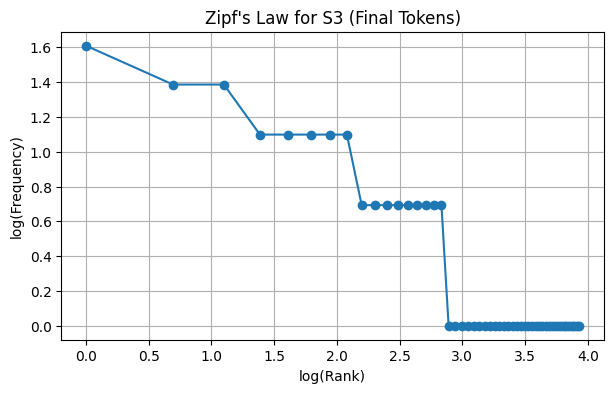

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

S1 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]]
S4 = [porter.stem(t) for t in S3]

def calc_ttr(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    return tot, uniq, round(uniq / tot, 4) if tot > 0 else 0

ttr_table = pd.DataFrame([
    {"Corpus": "S1 (All Tokens)", **dict(zip(["Tokens", "Unique", "TTR"], calc_ttr(S1)))},
    {"Corpus": "S2 (No Punctuation)", **dict(zip(["Tokens", "Unique", "TTR"], calc_ttr(S2)))},
    {"Corpus": "S3 (Final Tokens)", **dict(zip(["Tokens", "Unique", "TTR"], calc_ttr(S3)))},
    {"Corpus": "S4 (S3 + Porter)", **dict(zip(["Tokens", "Unique", "TTR"], calc_ttr(S4)))},
])

print("--- CORPUS METRICS ---")
print(ttr_table.to_string(index=False))
print("\nTop 10 Words in S1:", Counter(S1).most_common(10))
print("Top 10 Words in S3:", Counter(S3).most_common(10))
print("\nTop 5 Bigrams in S1:", Counter(list(ngrams(S1, 2))).most_common(5))
print("Top 5 Bigrams in S3:", Counter(list(ngrams(S3, 2))).most_common(5))

freqs = [count for word, count in Counter(S3).most_common()]
ranks = list(range(1, len(freqs) + 1))

plt.figure(figsize=(7, 4))
plt.plot(np.log(ranks), np.log(freqs), marker='o')
plt.xlabel('log(Rank)')
plt.ylabel('log(Frequency)')
plt.title('Zipf\'s Law for S3 (Final Tokens)')
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR = Unique Tokens/Total Tokens shifts across corpus stages: From S1 to S3, total tokens drop rapidly as non-informative punctuation and repetitive stopwords are removed. Since stopwords account for a heavy portion of repeated tokens, removing them increases the concentration of distinct vocabulary words, causing TTR to rise.   From S3 to S4, Porter Stemming collapses inflectional variations (such as crashes -> crash, opening -> open) down to identical base stems. This decreases the unique token count while keeping the total token count unchanged, causing TTR to decrease slightly.